In [1]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')


Hugging Face login: OK


In [2]:
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]


Analyzing Layer 0 q_proj...
Minimum rank for 50% energy: 62


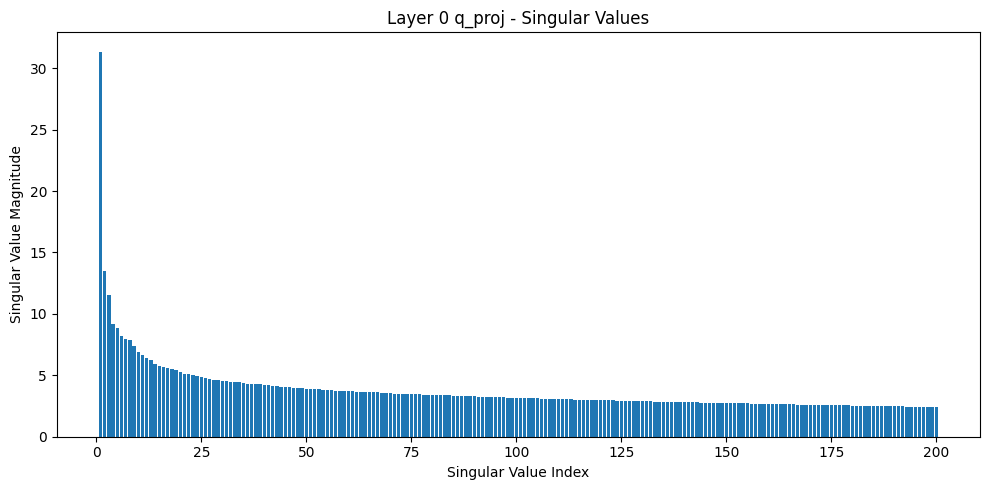

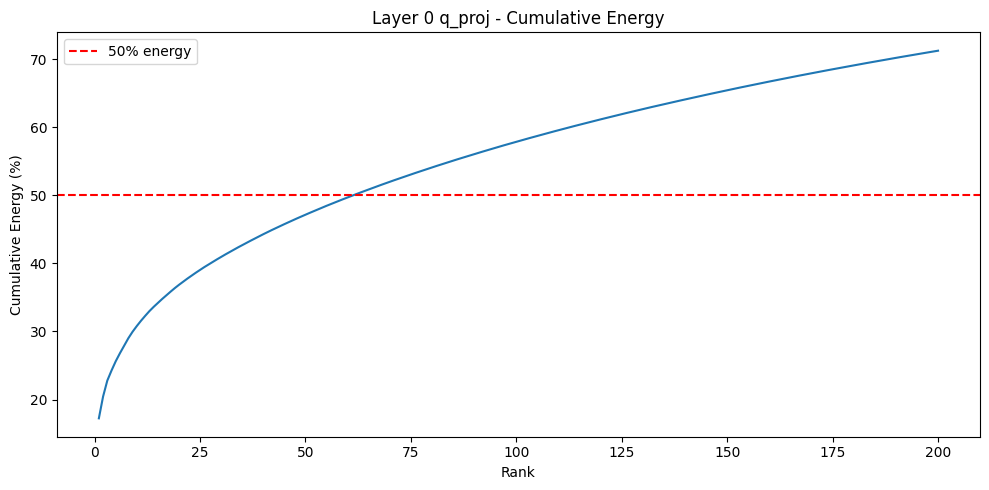


Analyzing Layer 7 q_proj...
Minimum rank for 50% energy: 120


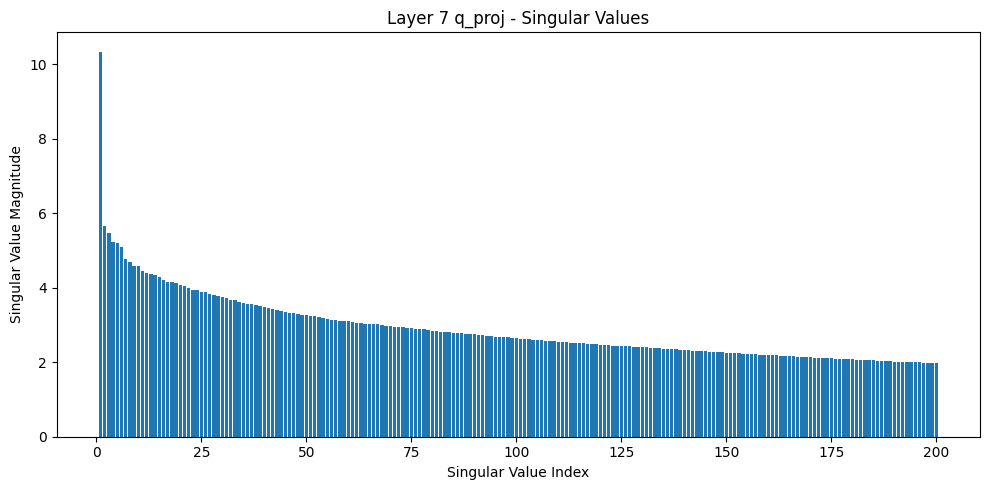

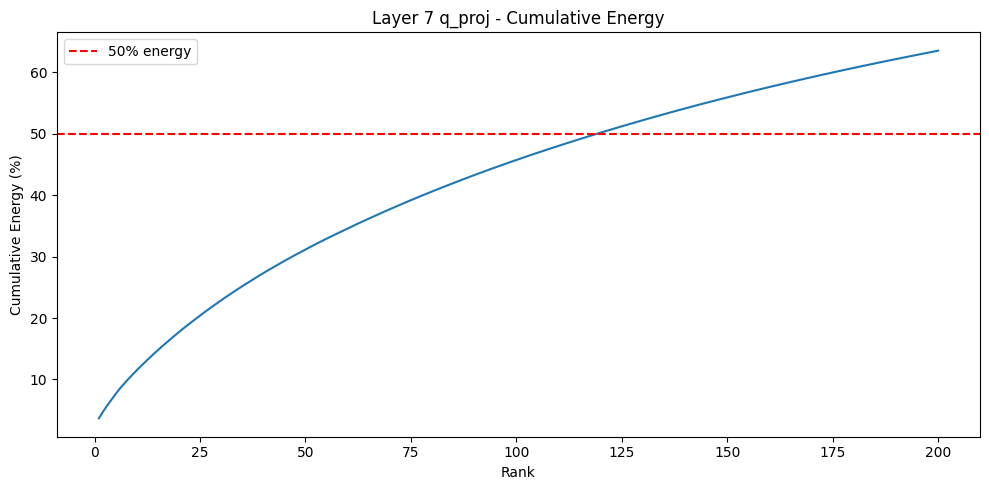


Analyzing Layer 15 q_proj...
Minimum rank for 50% energy: 84


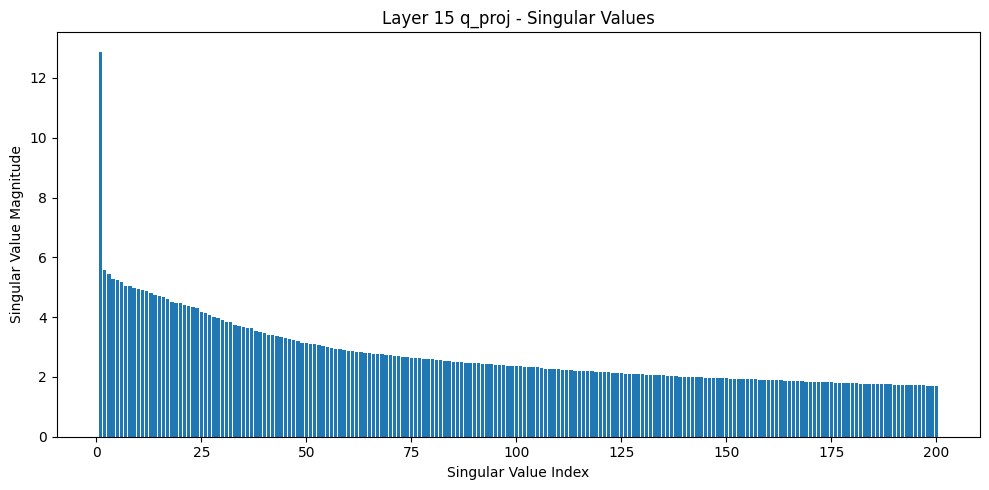

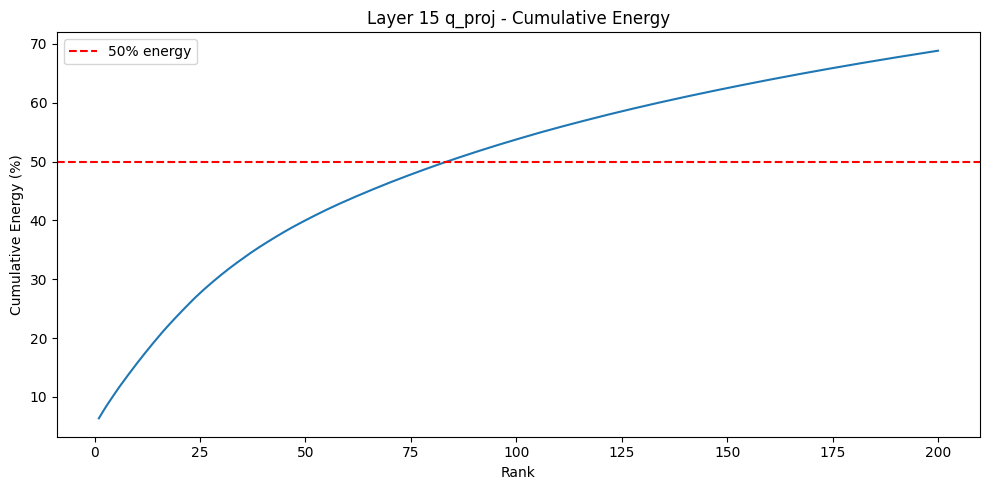


Q4 Results:


,layer,min_rank_50_percent
0,0,62
1,7,120
2,15,84


Saved results to: /kaggle/working/Q4_results


In [3]:
# TODO for Question 4
"""

Hint:
# Analyze the weights of the query projection layer (q_proj) where layer = k
 q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).
 U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

# Compute the retained energy ratio (Cumulative energy) of each singular value.
energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
"""

import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path('/kaggle/working/Q4_results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

layers_to_analyze = [0, 7, 15]
results = []

for k in layers_to_analyze:
    print(f'\nAnalyzing Layer {k} q_proj...')

    # Get q_proj weight matrix
    q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

    # Singular Value Decomposition
    U, S, Vh = torch.linalg.svd(
        q_weight.float(), full_matrices=False
    )

    # Cumulative energy percentage
    energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100

    # Minimum rank to reach at least 50% energy
    min_rank = int(torch.searchsorted(
        energy_ratios.contiguous(),
        torch.tensor(50.0, device=energy_ratios.device)
    ).item()) + 1

    results.append({
        'layer': k,
        'min_rank_50_percent': min_rank
    })

    print(f'Minimum rank for 50% energy: {min_rank}')

    # First 200 singular values
    n = min(200, len(S))
    x = range(1, n + 1)

    # Bar chart: singular value magnitudes
    plt.figure(figsize=(10, 5))
    plt.bar(x, S[:n].cpu().numpy())
    plt.xlabel('Singular Value Index')
    plt.ylabel('Singular Value Magnitude')
    plt.title(f'Layer {k} q_proj - Singular Values')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'layer_{k}_singular_values.png', dpi=200)
    plt.show()
    plt.close()

    # Line chart: cumulative energy
    plt.figure(figsize=(10, 5))
    plt.plot(x, energy_ratios[:n].cpu().numpy())
    plt.axhline(50, color='red', linestyle='--', label='50% energy')
    plt.xlabel('Rank')
    plt.ylabel('Cumulative Energy (%)')
    plt.title(f'Layer {k} q_proj - Cumulative Energy')
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'layer_{k}_cumulative_energy.png', dpi=200)
    plt.show()
    plt.close()

# Save results
results_df = pd.DataFrame(results)
print('\nQ4 Results:')
display(results_df)

results_df.to_csv(
    OUTPUT_DIR / 'q4_minimum_ranks.csv',
    index=False
)

print('Saved results to:', OUTPUT_DIR)
